In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/reubensuju/celeb-df-v2/List_of_testing_videos.txt
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0002.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0003.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0004.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0005.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0006.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0007.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0008.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0009.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0000.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0001.mp4
/kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id10_0002.mp4
/kaggle/input/

In [2]:
# ============================================================
# ENVIRONMENT SETUP — run this first, every session
# --no-deps is deliberate: prevents facenet-pytorch from pulling in a
# different numpy/torch/torchvision/Pillow than what Kaggle already has
# installed together (and already mutually compatible). Letting pip's
# resolver touch those is what caused the numpy ABI corruption and the
# Pillow/torchvision conflict in earlier attempts.
# ============================================================
!pip install -q --no-deps facenet-pytorch==2.6.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 22.2 MB/s eta 0:00:00


In [3]:
# ============================================================
# PATCH: restore is_directory/is_path to PIL._util BEFORE importing
# torchvision. Newer Pillow (needed by facenet-pytorch) removed these,
# which breaks torchvision's ImageFont import chain. This is not
# fixable by picking a Pillow/torchvision version — no compatible pair
# exists — so we patch the two missing functions back in directly.
# ============================================================
import os
import PIL._util as _util

if not hasattr(_util, "is_directory"):
    _util.is_directory = lambda path: os.path.isdir(path)
if not hasattr(_util, "is_path"):
    _util.is_path = lambda path: isinstance(path, (bytes, str, os.PathLike))

import torch, torchvision, PIL
import importlib.metadata

print("Torch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Pillow:", PIL.__version__)
print("facenet-pytorch:", importlib.metadata.version("facenet-pytorch"))
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

from facenet_pytorch import MTCNN
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_test_mtcnn = MTCNN(keep_all=True, device=device)
print("facenet-pytorch import + MTCNN init: OK")

Torch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
Pillow: 11.3.0
facenet-pytorch: 2.6.0
CUDA available: True
GPU: Tesla T4
facenet-pytorch import + MTCNN init: OK


In [4]:
# ============================================================
# LOAD SHARED PROJECT UTILITIES
# ============================================================
import os, sys

REPO_URL = "https://github.com/Mugdha-Naik/deepfake-detector-project.git"
REPO_DIR = "/kaggle/working/repo"

if not os.path.exists(REPO_DIR):
    os.system(f"git clone {REPO_URL} {REPO_DIR}")
else:
    os.system(f"cd {REPO_DIR} && git pull")

sys.path.append(REPO_DIR)

from utils import (
    get_kaggle_video_path, verify_path_resolution, get_label_from_path,
    load_mtcnn, extract_faces_from_video, apply_quality_filters,
    CELEB_ROOT, FF_ROOT, CSV_URL,
)

print("utils.py loaded successfully")

Cloning into '/kaggle/working/repo'...


utils.py loaded successfully


In [5]:
import cv2
import numpy as np
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm

print("Celeb-DF exists:", os.path.exists(CELEB_ROOT))
print("FF++ exists:", os.path.exists(FF_ROOT))


Celeb-DF exists: True
FF++ exists: True


In [6]:
# ============================================================
# LOAD VIDEO LIST + LABEL + DATASET SOURCE
# `dataset` is derived from the ORIGINAL CSV path (e.g. data/raw\cel\...),
# NOT from the resolved Kaggle path, so the "/cel/" marker is reliable here.
# ============================================================
df = pd.read_csv(CSV_URL)
df["kaggle_path"] = df["video_path"].apply(get_kaggle_video_path)
df["label_name"] = df["video_path"].apply(get_label_from_path)

def get_dataset_source(csv_path):
    p = str(csv_path).lower().replace("\\", "/")
    return "Celeb-DF" if "/cel/" in p else "FaceForensics++"

df["dataset"] = df["video_path"].apply(get_dataset_source)

print("Total videos:", len(df))
print("\nVideos per dataset x label:")
print(df.groupby(["dataset", "label_name"]).size())

# Guard: all four groups must exist
_groups = set(map(tuple, df[["dataset", "label_name"]].drop_duplicates().values))
_expected = {(d, l) for d in ["Celeb-DF", "FaceForensics++"] for l in ["REAL", "FAKE"]}
assert _groups == _expected, f"Missing/unexpected groups: {_groups ^ _expected}"

Total videos: 13529

Videos per dataset x label:
dataset          label_name
Celeb-DF         FAKE          5639
                 REAL           890
FaceForensics++  FAKE          6000
                 REAL          1000
dtype: int64


In [7]:
# ============================================================
# VERIFY: check both REAL and FAKE paths resolve correctly
# ============================================================
verify_path_resolution(df)


data/raw\cel\Celeb-real\id0_0000.mp4 -> /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0000.mp4 | exists: True
data/raw\cel\Celeb-real\id0_0001.mp4 -> /kaggle/input/datasets/reubensuju/celeb-df-v2/Celeb-real/id0_0001.mp4 | exists: True
data/raw\FaceForensics++_C23\DeepFakeDetection\01_02__meeting_serious__YVGY8LOK.mp4 -> /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__meeting_serious__YVGY8LOK.mp4 | exists: True
data/raw\FaceForensics++_C23\DeepFakeDetection\01_02__outside_talking_still_laughing__YVGY8LOK.mp4 -> /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23/DeepFakeDetection/01_02__outside_talking_still_laughing__YVGY8LOK.mp4 | exists: True


In [8]:
# ============================================================
# STRATIFIED SAMPLE (dataset x label)
# Edit SAMPLE_PLAN to scale up. Suggested real run:
#   FF++ (train + Exp A/B): 300 REAL, 300 FAKE
#   Celeb-DF (test only, Exp C/D): 150 REAL, 150 FAKE  (REAL max = 890)
# ============================================================
SAMPLE_PLAN = {
    ("FaceForensics++", "REAL"): 10,
    ("FaceForensics++", "FAKE"): 10,
    ("Celeb-DF",        "REAL"): 10,
    ("Celeb-DF",        "FAKE"): 10,
}

parts = []
for (ds, lab), n in SAMPLE_PLAN.items():
    pool = df[(df["dataset"] == ds) & (df["label_name"] == lab)]
    parts.append(pool.sample(n=min(n, len(pool)), random_state=42))

run_df = (pd.concat(parts)
            .sample(frac=1, random_state=42)
            .reset_index(drop=True))      # unique index -> unique video_id

print("Total videos selected:", len(run_df))
print(run_df.groupby(["dataset", "label_name"]).size())


Total videos selected: 40
dataset          label_name
Celeb-DF         FAKE          10
                 REAL          10
FaceForensics++  FAKE          10
                 REAL          10
dtype: int64


In [9]:
mtcnn, device = load_mtcnn()

MTCNN loaded. Device: cuda


In [10]:
OUTPUT_DIR = "/kaggle/working/step5_faces"
FACES_DIR = os.path.join(OUTPUT_DIR, "faces")
os.makedirs(FACES_DIR, exist_ok=True)
print("Faces directory:", FACES_DIR)

Faces directory: /kaggle/working/step5_faces/faces


In [11]:
# ============================================================
# MAIN EXTRACTION LOOP (stratified, labeled, dataset-tagged)
# sampling="interval" matches Step 4's convention.
# ============================================================
all_records = []

for idx, row in tqdm(run_df.iterrows(), total=len(run_df), desc="Step 5 extraction"):
    video_path = row["kaggle_path"]
    label_name = row["label_name"]

    if not video_path or not os.path.exists(video_path):
        print("Video not found:", row["video_path"])
        continue

    video_id = f"video_{idx}"

    records = extract_faces_from_video(
        video_path=video_path,
        label_name=label_name,
        faces_dir=FACES_DIR,
        video_id=video_id,
        mtcnn=mtcnn,
        sampling="interval",
    )

    # carry dataset source + video id into every face record
    for r in records:
        r["dataset"] = row["dataset"]
        r["video_id"] = video_id
    all_records.extend(records)

step5_df = pd.DataFrame(all_records)

print("=" * 60)
print("EXTRACTION COMPLETE")
print("Face crops:", len(step5_df))
print(step5_df.groupby(["dataset", "label_name"]).size())

Step 5 extraction:   0%|          | 0/40 [00:00<?, ?it/s]

EXTRACTION COMPLETE
Face crops: 1975
dataset          label_name
Celeb-DF         FAKE          380
                 REAL          405
FaceForensics++  FAKE          716
                 REAL          474
dtype: int64


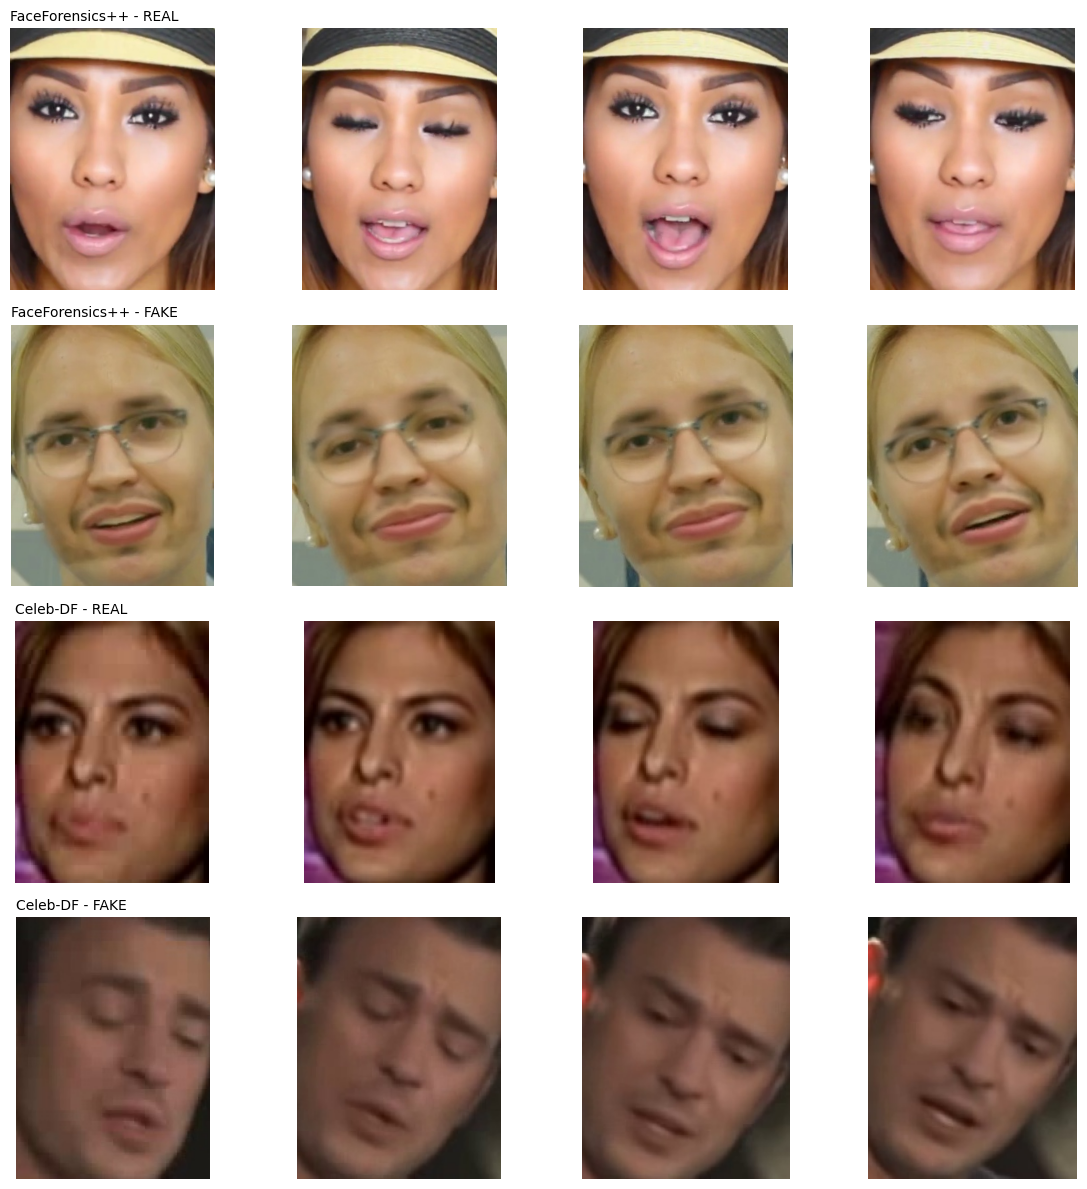

In [12]:
# ============================================================
# SANITY CHECK — view saved face crops for each dataset x label group
# ============================================================
import matplotlib.pyplot as plt

groups = [("FaceForensics++", "REAL"), ("FaceForensics++", "FAKE"),
          ("Celeb-DF", "REAL"), ("Celeb-DF", "FAKE")]
N_PER_ROW = 4

fig, axes = plt.subplots(len(groups), N_PER_ROW, figsize=(12, 12))
for r, (ds, lab) in enumerate(groups):
    paths = step5_df[(step5_df["dataset"] == ds) & (step5_df["label_name"] == lab)]["face_path"].head(N_PER_ROW).tolist()
    for c in range(N_PER_ROW):
        ax = axes[r][c]
        ax.axis("off")
        if c < len(paths):
            ax.imshow(Image.open(paths[c]))
        if c == 0:
            ax.set_title(f"{ds} - {lab}", fontsize=10, loc="left")
plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# QUALITY FLAGGING
# - blur_score / blur_pass are computed by utils.apply_quality_filters
#   but blur is NOT used to drop faces (blur is a dataset/compression
#   signal here, and a threshold of 50 wiped out Celeb-DF + most FAKE).
# - Only the SIZE filter removes faces.
# ============================================================
step5_df, _ = apply_quality_filters(step5_df)

step5_df["quality_pass"] = step5_df["size_pass"]          # size only; blur is a flag
quality_filtered_df = step5_df[step5_df["quality_pass"]].copy()

total_in = len(step5_df)
flagged_blur = int((~step5_df["blur_pass"]).sum())         # flagged, still KEPT
dropped_size = int((~step5_df["size_pass"]).sum())         # actually removed
remaining = int(step5_df["quality_pass"].sum())

print("=" * 60)
print("QUALITY FILTERING RESULT")
print("=" * 60)
print("Total faces in:", total_in)
print("Flagged as low-blur (kept):", flagged_blur)
print("Dropped due to size:", dropped_size)
print("Remaining:", remaining)
print(f"Percentage dropped: {round((total_in - remaining) / total_in * 100, 2)}%")

QUALITY FILTERING RESULT
Total faces in: 1975
Flagged as low-blur (kept): 1047
Dropped due to size: 0
Remaining: 1975
Percentage dropped: 0.0%


In [14]:
# ============================================================
# BLUR DISTRIBUTION BY GROUP (documents why blur is not a filter)
# ============================================================
blur_stats = (step5_df.groupby(["dataset", "label_name"])["blur_score"]
                .describe(percentiles=[.1, .25, .5, .75, .9]).round(1))
blur_stats["blur_pass_rate"] = (step5_df.groupby(["dataset", "label_name"])["blur_pass"].mean().round(2))
blur_stats

count   mean    std   min   10%   25%   50%  \
dataset         label_name                                                
Celeb-DF        FAKE        380.0   38.9   25.5   8.7  13.9  17.7  32.9   
                REAL        405.0   39.2   25.5  11.6  17.1  26.1  33.0   
FaceForensics++ FAKE        716.0  102.6   74.6   5.0  17.2  27.9  97.1   
                REAL        474.0  119.2  151.0   6.9  23.4  41.8  64.7   

                              75%    90%    max  blur_pass_rate  
dataset         label_name                                       
Celeb-DF        FAKE         52.0   70.0  121.1            0.26  
                REAL         41.9   65.1  141.4            0.14  
FaceForensics++ FAKE        149.5  194.5  425.3            0.65  
                REAL         98.8  412.1  694.7            0.65

In [15]:
# ============================================================
# PER dataset x CLASS SUMMARY
# ============================================================
class_summary = []

for (ds, label), g in step5_df.groupby(["dataset", "label_name"]):
    kept = g[g["quality_pass"]]
    class_summary.append({
        "dataset": ds,
        "class": label,
        "videos": g["video_id"].nunique(),
        "total_in": len(g),
        "flagged_blur_kept": int((~g["blur_pass"]).sum()),
        "dropped_size": int((~g["size_pass"]).sum()),
        "remaining": len(kept),
        "drop_percentage": round((len(g) - len(kept)) / len(g) * 100, 2) if len(g) else 0,
    })

class_summary_df = pd.DataFrame(class_summary)
class_summary_df

,dataset,class,videos,total_in,flagged_blur_kept,dropped_size,remaining,drop_percentage
0,Celeb-DF,FAKE,10,380,280,0,380,0.0
1,Celeb-DF,REAL,10,405,350,0,405,0.0
2,FaceForensics++,FAKE,10,716,252,0,716,0.0
3,FaceForensics++,REAL,10,474,165,0,474,0.0


In [16]:
# ============================================================
# SAVE FINAL OUTPUTS
# ============================================================
STEP5_DIR = "/kaggle/working/step5_quality"
os.makedirs(STEP5_DIR, exist_ok=True)

FILTERED_PATH = os.path.join(STEP5_DIR, "quality_filtered_faces.csv")
quality_filtered_df.to_csv(FILTERED_PATH, index=False)

CLASS_SUMMARY_PATH = os.path.join(STEP5_DIR, "step5_class_summary.csv")
class_summary_df.to_csv(CLASS_SUMMARY_PATH, index=False)

BLUR_STATS_PATH = os.path.join(STEP5_DIR, "step5_blur_stats.csv")
blur_stats.to_csv(BLUR_STATS_PATH)

overall_summary = pd.DataFrame([{
    "total_faces_in": total_in,
    "flagged_blur_kept": flagged_blur,
    "dropped_size": dropped_size,
    "remaining": remaining,
    "percentage_dropped": round((total_in - remaining) / total_in * 100, 2)
}])
OVERALL_SUMMARY_PATH = os.path.join(STEP5_DIR, "step5_overall_summary.csv")
overall_summary.to_csv(OVERALL_SUMMARY_PATH, index=False)

print("Saved:")
for p in [FILTERED_PATH, CLASS_SUMMARY_PATH, BLUR_STATS_PATH, OVERALL_SUMMARY_PATH]:
    print(" ", p)

Saved:
  /kaggle/working/step5_quality/quality_filtered_faces.csv
  /kaggle/working/step5_quality/step5_class_summary.csv
  /kaggle/working/step5_quality/step5_blur_stats.csv
  /kaggle/working/step5_quality/step5_overall_summary.csv


In [17]:
print("=" * 60)
print("STEP 5 FINAL CHECK")
print("=" * 60)
print("Final face count:", len(quality_filtered_df))

print("\nFaces per dataset x label:")
print(quality_filtered_df.groupby(["dataset", "label_name"]).size())

print("\nVideos per dataset x label:")
print(quality_filtered_df.groupby(["dataset", "label_name"])["video_path"].nunique())

print("\nFinal REAL/FAKE distribution:")
print(quality_filtered_df["label_name"].value_counts())

# Guard: every group must still have faces
_final = set(map(tuple, quality_filtered_df[["dataset", "label_name"]].drop_duplicates().values))
assert _final == _expected, f"Group(s) empty after filtering: {_final ^ _expected}"

STEP 5 FINAL CHECK
Final face count: 1975

Faces per dataset x label:
dataset          label_name
Celeb-DF         FAKE          380
                 REAL          405
FaceForensics++  FAKE          716
                 REAL          474
dtype: int64

Videos per dataset x label:
dataset          label_name
Celeb-DF         FAKE          10
                 REAL          10
FaceForensics++  FAKE          10
                 REAL          10
Name: video_path, dtype: int64

Final REAL/FAKE distribution:
label_name
FAKE    1096
REAL     879
Name: count, dtype: int64
